# IT3212 - Assignment 3 - Task 9: Deep Neural Network

Tuned MLP that predicts never vs. ever smoked from health-check measurements.

Input: `task4_{train,val,test}.csv` (18 features). Output: `task9_metrics.json`.

## 0. Setup

In [1]:
# %pip install torch optuna scikit-learn pandas numpy matplotlib

In [2]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.preprocessing import StandardScaler

print(f"torch  {torch.__version__}")
print(f"optuna {optuna.__version__}")

torch  2.14.1
optuna 5.0.0


### Configuration

Set `QUICK_RUN = True` for a fast test run.

In [3]:
QUICK_RUN = False  # set to False for full run

RANDOM_STATE = 42
IN_DIR = Path("../data/assignment3")
OUT_DIR = Path("../data/assignment3")

if QUICK_RUN:
    TUNE_SAMPLE = 30_000
    N_TRIALS = 6
    TUNE_MAX_EPOCHS = 4
    TUNE_PATIENCE = 2
    FINAL_MAX_EPOCHS = 4
    FINAL_PATIENCE = 2
else:
    TUNE_SAMPLE = 200_000      # rows of train used during tuning
    N_TRIALS = 40              # Optuna trials
    TUNE_MAX_EPOCHS = 25       # upper bound per trial (early stopping usually ends sooner)
    TUNE_PATIENCE = 4
    FINAL_MAX_EPOCHS = 60
    FINAL_PATIENCE = 6

TUNING_TIMEOUT = 2 * 60 * 60   # safety limit for the whole study, in seconds

In [4]:
def set_seed(seed: int = RANDOM_STATE) -> None:
    # Fix all random sources so the results are reproducible.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():   # Apple Silicon
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Device: {DEVICE}")

Device: mps


## 1. Model choice

MLP rather than CNN: the data is tabular, and the column order has no spatial meaning.

## 2. Load and scale the data

`StandardScaler` fitted on train only; `sex` is not scaled.

In [5]:
with open(IN_DIR / "task4_metadata.json") as f:
    meta = json.load(f)

TARGET = meta["target"]
FEATURES = meta["selected_features"]
SCALE_COLS = meta["scaling"]["columns"]

splits = {
    name: pd.read_csv(IN_DIR / f"task4_{name}.csv")
    for name in ["train", "val", "test"]
}

for name, d in splits.items():
    print(f"{name:5s}: {d.shape[0]:>7,} rows x {d.shape[1] - 1} features | ever ratio = {d[TARGET].mean():.4f}")

print(f"\nScaled columns  : {len(SCALE_COLS)}")
print(f"Unscaled columns: {[c for c in FEATURES if c not in SCALE_COLS]}")

train: 787,625 rows x 18 features | ever ratio = 0.3920
val  :  98,453 rows x 18 features | ever ratio = 0.3920
test :  98,454 rows x 18 features | ever ratio = 0.3920

Scaled columns  : 17
Unscaled columns: ['sex']


In [6]:
scaler = StandardScaler()
scaler.fit(splits["train"][SCALE_COLS])          # train only

def to_arrays(d: pd.DataFrame):
    X = d[FEATURES].copy()
    X[SCALE_COLS] = scaler.transform(X[SCALE_COLS])
    return X.to_numpy(np.float32), d[TARGET].to_numpy(np.float32)

X_train, y_train = to_arrays(splits["train"])
X_val, y_val = to_arrays(splits["val"])
X_test, y_test = to_arrays(splits["test"])

# Sanity check: scaled training columns have mean ~0 and std ~1
scaled_idx = [FEATURES.index(c) for c in SCALE_COLS]
print(f"train mean (scaled cols): {X_train[:, scaled_idx].mean():+.4f}")
print(f"train std  (scaled cols): {X_train[:, scaled_idx].std():.4f}")

train mean (scaled cols): +0.0000
train std  (scaled cols): 1.0000


In [7]:
# Stratified subsample of the training set used only during tuning (section 4)
rng = np.random.RandomState(RANDOM_STATE)
pos_idx = np.where(y_train == 1)[0]
neg_idx = np.where(y_train == 0)[0]
n_pos = int(round(TUNE_SAMPLE * y_train.mean()))
tune_idx = np.concatenate([
    rng.choice(pos_idx, n_pos, replace=False),
    rng.choice(neg_idx, TUNE_SAMPLE - n_pos, replace=False),
])
rng.shuffle(tune_idx)

X_tune, y_tune = X_train[tune_idx], y_train[tune_idx]
print(f"Tuning sample: {len(X_tune):,} rows | ever ratio = {y_tune.mean():.4f}")

# Move everything to tensors once
def tensors(X, y):
    return torch.from_numpy(X).to(DEVICE), torch.from_numpy(y).to(DEVICE)

Xt_train, yt_train = tensors(X_train, y_train)
Xt_tune, yt_tune = tensors(X_tune, y_tune)
Xt_val, yt_val = tensors(X_val, y_val)
Xt_test, yt_test = tensors(X_test, y_test)

Tuning sample: 200,000 rows | ever ratio = 0.3920


## 3. Model and training function

`[Linear -> BatchNorm -> ReLU -> Dropout] x n_layers -> Linear(1)`, weighted BCE loss, AdamW, early stopping on validation loss.

In [8]:
POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"pos_weight = {POS_WEIGHT:.3f}")


def build_mlp(n_inputs: int, n_layers: int, units: int, dropout: float) -> nn.Sequential:
    layers = []
    width_in = n_inputs
    for _ in range(n_layers):
        layers += [
            nn.Linear(width_in, units),
            nn.BatchNorm1d(units),
            nn.ReLU(),
            nn.Dropout(dropout),
        ]
        width_in = units
    layers.append(nn.Linear(width_in, 1))     # logit; sigmoid is applied in the loss / at prediction
    return nn.Sequential(*layers)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def predict_logits(model, X, batch_size=16_384):
    model.eval()
    return torch.cat([model(X[i:i + batch_size]).squeeze(1) for i in range(0, len(X), batch_size)])


def predict_proba(model, X) -> np.ndarray:
    return torch.sigmoid(predict_logits(model, X)).cpu().numpy()


print(build_mlp(len(FEATURES), n_layers=2, units=64, dropout=0.2))

pos_weight = 1.551
Sequential(
  (0): Linear(in_features=18, out_features=64, bias=True)
  (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.2, inplace=False)
  (8): Linear(in_features=64, out_features=1, bias=True)
)


In [9]:
def train_model(params, X_tr, y_tr, X_va, y_va, max_epochs, patience, trial=None, verbose=False):
    # Train one MLP with early stopping on validation loss.
    # If an Optuna trial is given, the validation AUC is reported after every
    # epoch so that unpromising trials can be pruned (stopped early).
    set_seed()
    model = build_mlp(X_tr.shape[1], params["n_layers"], params["units"], params["dropout"]).to(DEVICE)
    optimiser = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))

    generator = torch.Generator().manual_seed(RANDOM_STATE)
    bs = params["batch_size"]
    y_va_np = y_va.cpu().numpy()

    best_loss, best_auc, best_state, best_epoch = np.inf, None, None, 0
    history = []
    epochs_without_improvement = 0
    t0 = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        order = torch.randperm(len(X_tr), generator=generator).to(DEVICE)
        running = 0.0
        for i in range(0, len(X_tr), bs):
            idx = order[i:i + bs]
            if len(idx) < 2:          # BatchNorm needs more than one row
                continue
            optimiser.zero_grad()
            loss = loss_fn(model(X_tr[idx]).squeeze(1), y_tr[idx])
            loss.backward()
            optimiser.step()
            running += loss.item() * len(idx)
        train_loss = running / len(X_tr)

        val_logits = predict_logits(model, X_va)
        val_loss = loss_fn(val_logits, y_va).item()
        val_auc = roc_auc_score(y_va_np, val_logits.cpu().numpy())
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_auc": val_auc})

        if verbose:
            print(f"epoch {epoch:>3} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val AUC {val_auc:.4f}")

        if val_loss < best_loss - 1e-5:
            best_loss, best_auc, best_epoch = val_loss, val_auc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if trial is not None:
            trial.report(val_auc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)
    return {
        "model": model,
        "history": pd.DataFrame(history),
        "best_val_auc": best_auc,
        "best_val_loss": best_loss,
        "best_epoch": best_epoch,
        "epochs_run": len(history),
        "train_time_s": time.perf_counter() - t0,
    }

## 4. Hyperparameter tuning

Optuna (TPE + median pruning) on a 200k-row stratified sample, maximising validation AUC.

In [10]:
def objective(trial: optuna.Trial) -> float:
    params = {
        "n_layers": trial.suggest_int("n_layers", 1, 5),
        "units": trial.suggest_int("units", 32, 512, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024, 2048]),
    }
    result = train_model(
        params, Xt_tune, yt_tune, Xt_val, yt_val,
        max_epochs=TUNE_MAX_EPOCHS, patience=TUNE_PATIENCE, trial=trial,
    )
    trial.set_user_attr("epochs_run", result["epochs_run"])
    trial.set_user_attr("train_time_s", result["train_time_s"])
    trial.set_user_attr("n_params", count_params(result["model"]))
    return result["best_val_auc"]


def log_trial(study, trial):
    if trial.state == optuna.trial.TrialState.COMPLETE:
        print(f"trial {trial.number:>3} | AUC {trial.value:.5f} | best {study.best_value:.5f} | "
              f"{trial.user_attrs['epochs_run']:>2} epochs | {trial.user_attrs['train_time_s']:6.1f}s | {trial.params}")
    elif trial.state == optuna.trial.TrialState.PRUNED:
        print(f"trial {trial.number:>3} | pruned")


optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    study_name="task9_mlp",
)

t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TUNING_TIMEOUT, callbacks=[log_trial])
TUNING_TIME_S = time.perf_counter() - t0

states = [t.state for t in study.trials]
N_COMPLETE = states.count(optuna.trial.TrialState.COMPLETE)
N_PRUNED = states.count(optuna.trial.TrialState.PRUNED)
print(f"\nTuning finished in {TUNING_TIME_S / 60:.1f} min | {N_COMPLETE} complete, {N_PRUNED} pruned")

trial   0 | AUC 0.88029 | best 0.88029 | 17 epochs |   25.9s | {'n_layers': 2, 'units': 447, 'dropout': 0.36599697090570255, 'lr': 0.0015751320499779737, 'weight_decay': 2.9380279387035354e-06, 'batch_size': 1024}
trial   1 | AUC 0.87732 | best 0.88029 | 20 epochs |   12.6s | {'n_layers': 4, 'units': 33, 'dropout': 0.48495492608099716, 'lr': 0.004622589001020831, 'weight_decay': 4.335281794951567e-06, 'batch_size': 2048}
trial   2 | AUC 0.87893 | best 0.88029 | 25 epochs |   24.5s | {'n_layers': 3, 'units': 71, 'dropout': 0.30592644736118974, 'lr': 0.00019010245319870352, 'weight_decay': 7.523742884534855e-06, 'batch_size': 1024}
trial   3 | AUC 0.87994 | best 0.88029 | 10 epochs |    8.9s | {'n_layers': 3, 'units': 164, 'dropout': 0.023225206359998862, 'lr': 0.0016409286730647919, 'weight_decay': 3.247673570627449e-06, 'batch_size': 1024}
trial   4 | AUC 0.87942 | best 0.88029 | 25 epochs |   17.5s | {'n_layers': 2, 'units': 41, 'dropout': 0.34211651325607845, 'lr': 0.0007591104805282

## 5. Tuning results

In [11]:
BEST_PARAMS = study.best_params
print(f"Best validation AUC (tuning sample): {study.best_value:.5f}\n")
print("Best hyperparameters:")
for k, v in BEST_PARAMS.items():
    print(f"  {k:13s} = {v:.2e}" if isinstance(v, float) and v < 0.01 else f"  {k:13s} = {v}")

trials_df = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
trials_df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials_df.columns]
trials_df[trials_df["state"] == "COMPLETE"].sort_values("value", ascending=False).head(10).round(5)

Best validation AUC (tuning sample): 0.88058

Best hyperparameters:
  n_layers      = 2
  units         = 509
  dropout       = 0.3070036035083961
  lr            = 3.10e-03
  weight_decay  = 3.88e-05
  batch_size    = 256


,number,value,batch_size,dropout,lr,n_layers,units,weight_decay,epochs_run,n_params,train_time_s,state
19,19,0.88058,256,0.30700,0.00310,2,509,0.00004,22.0,271807.0,63.49626,COMPLETE
28,28,0.88054,256,0.24381,0.00094,3,273,0.00000,19.0,156703.0,62.00309,COMPLETE
21,21,0.88043,256,0.24340,0.00186,4,412,0.00000,22.0,522005.0,99.08319,COMPLETE
11,11,0.88037,256,0.25644,0.00210,3,463,0.00000,13.0,441703.0,44.91487,COMPLETE
13,13,0.88030,1024,0.29256,0.00067,2,460,0.00000,21.0,223101.0,20.47117,COMPLETE
33,33,0.88030,256,0.22340,0.00515,4,469,0.00000,13.0,674423.0,71.98215,COMPLETE
14,14,0.88030,256,0.23729,0.00090,3,505,0.00000,13.0,524191.0,53.87395,COMPLETE
0,0,0.88029,1024,0.36600,0.00158,2,447,0.00000,17.0,210985.0,25.87113,COMPLETE
12,12,0.88018,256,0.20668,0.00294,3,231,0.00000,13.0,113191.0,46.03279,COMPLETE
22,22,0.88013,256,0.34273,0.00134,3,428,0.00001,13.0,378353.0,47.32946,COMPLETE


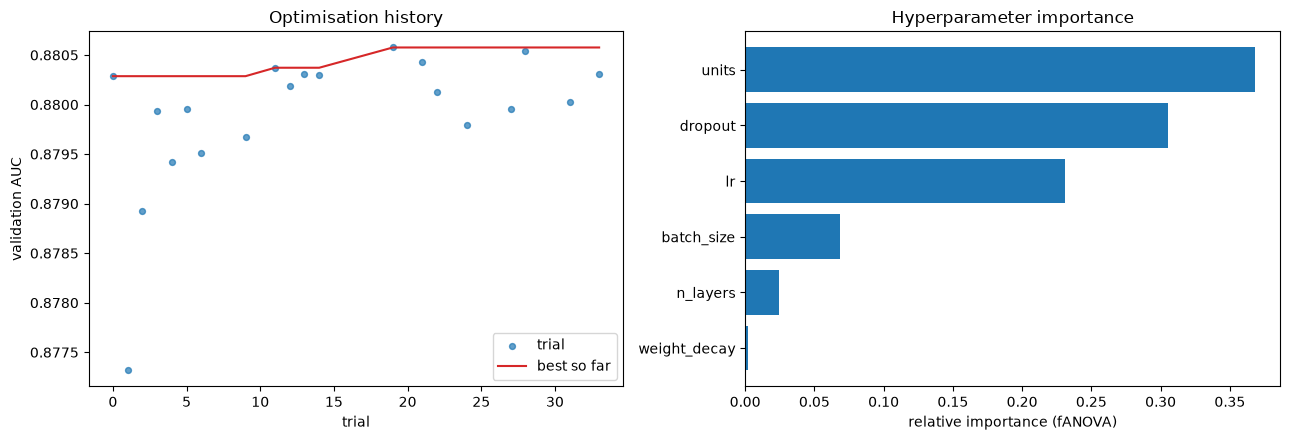

  units         0.368
  dropout       0.306
  lr            0.231
  batch_size    0.068
  n_layers      0.024
  weight_decay  0.002


In [12]:
importances = optuna.importance.get_param_importances(
    study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=RANDOM_STATE)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Optimisation history
complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
nums = [t.number for t in complete]
vals = [t.value for t in complete]
axes[0].scatter(nums, vals, s=18, alpha=0.7, label="trial")
axes[0].plot(nums, np.maximum.accumulate(vals), color="tab:red", label="best so far")
axes[0].set(xlabel="trial", ylabel="validation AUC", title="Optimisation history")
axes[0].legend()

# Hyperparameter importance
names = list(importances.keys())[::-1]
axes[1].barh(names, [importances[n] for n in names])
axes[1].set(xlabel="relative importance (fANOVA)", title="Hyperparameter importance")

plt.tight_layout()
plt.show()

for k, v in importances.items():
    print(f"  {k:13s} {v:.3f}")

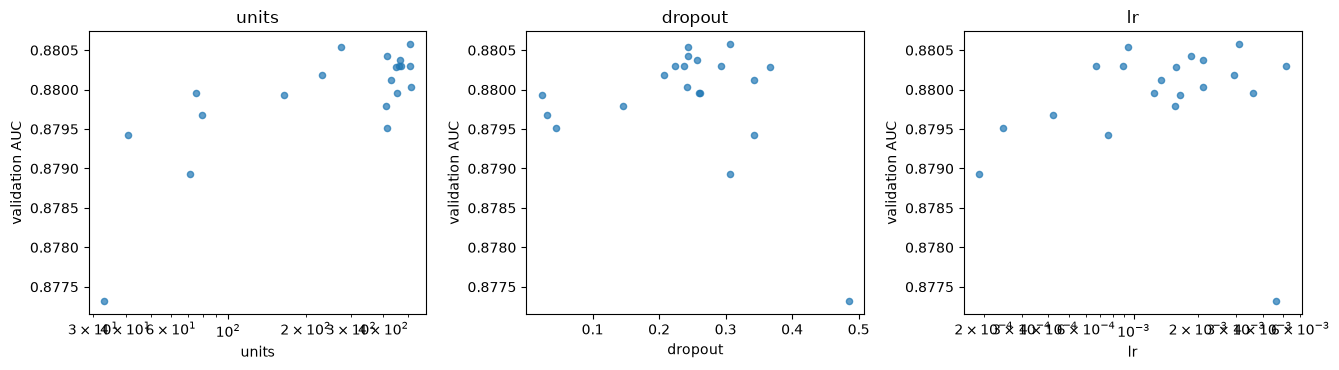

In [13]:
# How the most important hyperparameters relate to AUC
top = list(importances.keys())[:3]
done = trials_df[trials_df["state"] == "COMPLETE"]

fig, axes = plt.subplots(1, len(top), figsize=(4.5 * len(top), 3.8))
for ax, p in zip(np.atleast_1d(axes), top):
    ax.scatter(done[p], done["value"], s=20, alpha=0.7)
    if p in ("lr", "weight_decay", "units"):
        ax.set_xscale("log")
    ax.set(xlabel=p, ylabel="validation AUC", title=p)
plt.tight_layout()
plt.show()

## 6. Final model on the full training set

In [14]:
final = train_model(
    BEST_PARAMS, Xt_train, yt_train, Xt_val, yt_val,
    max_epochs=FINAL_MAX_EPOCHS, patience=FINAL_PATIENCE, verbose=True,
)
model = final["model"]
history = final["history"]
FINAL_TRAIN_TIME_S = final["train_time_s"]
N_PARAMS = count_params(model)

print(f"\nBest epoch {final['best_epoch']} of {final['epochs_run']} | "
      f"val AUC {final['best_val_auc']:.5f} | {FINAL_TRAIN_TIME_S / 60:.1f} min | {N_PARAMS:,} parameters")

epoch   1 | train loss 0.5121 | val loss 0.5051 | val AUC 0.8789
epoch   2 | train loss 0.5076 | val loss 0.5027 | val AUC 0.8800
epoch   3 | train loss 0.5063 | val loss 0.5029 | val AUC 0.8803
epoch   4 | train loss 0.5057 | val loss 0.5016 | val AUC 0.8807
epoch   5 | train loss 0.5054 | val loss 0.5032 | val AUC 0.8805
epoch   6 | train loss 0.5051 | val loss 0.5025 | val AUC 0.8806
epoch   7 | train loss 0.5050 | val loss 0.5042 | val AUC 0.8808
epoch   8 | train loss 0.5049 | val loss 0.5020 | val AUC 0.8808
epoch   9 | train loss 0.5045 | val loss 0.5017 | val AUC 0.8807
epoch  10 | train loss 0.5046 | val loss 0.5017 | val AUC 0.8807

Best epoch 4 of 10 | val AUC 0.88070 | 1.9 min | 271,807 parameters


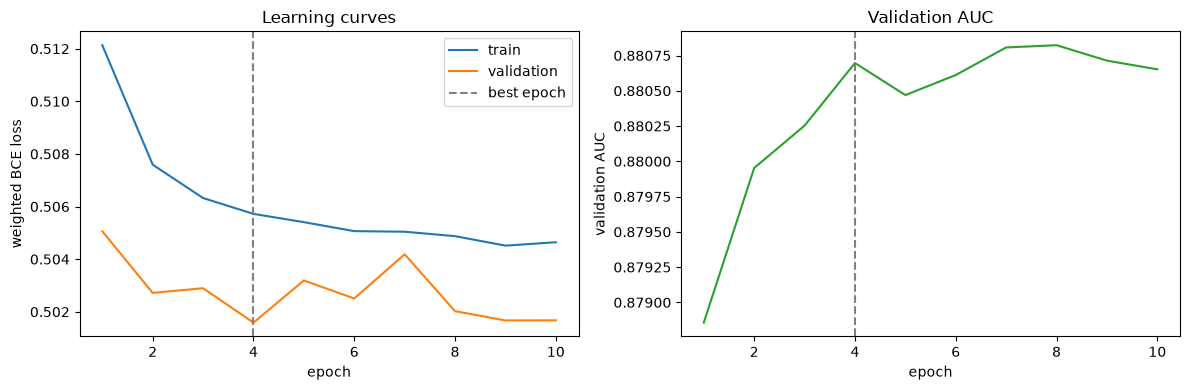

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], label="train")
axes[0].plot(history["epoch"], history["val_loss"], label="validation")
axes[0].axvline(final["best_epoch"], ls="--", c="grey", label="best epoch")
axes[0].set(xlabel="epoch", ylabel="weighted BCE loss", title="Learning curves")
axes[0].legend()

axes[1].plot(history["epoch"], history["val_auc"], c="tab:green")
axes[1].axvline(final["best_epoch"], ls="--", c="grey")
axes[1].set(xlabel="epoch", ylabel="validation AUC", title="Validation AUC")
plt.tight_layout()
plt.show()

## 7. Decision threshold

Chosen on the validation set to maximise F1.

Validation F1 at 0.50          : 0.79102
Validation F1 at best threshold: 0.79147 (threshold = 0.540)


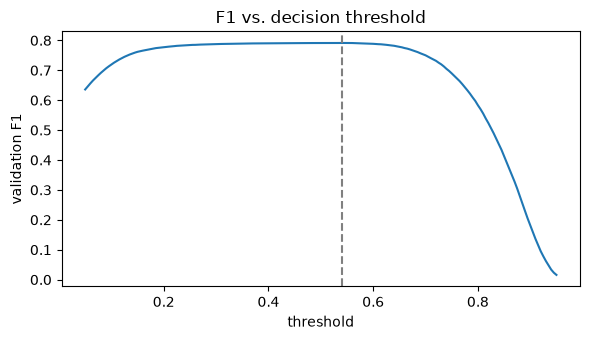

In [16]:
val_proba = predict_proba(model, Xt_val)
thresholds = np.linspace(0.05, 0.95, 181)
val_f1s = np.array([f1_score(y_val, val_proba >= t) for t in thresholds])

BEST_THRESHOLD = float(thresholds[val_f1s.argmax()])
print(f"Validation F1 at 0.50          : {f1_score(y_val, val_proba >= 0.5):.5f}")
print(f"Validation F1 at best threshold: {val_f1s.max():.5f} (threshold = {BEST_THRESHOLD:.3f})")

plt.figure(figsize=(6, 3.5))
plt.plot(thresholds, val_f1s)
plt.axvline(BEST_THRESHOLD, ls="--", c="grey")
plt.xlabel("threshold")
plt.ylabel("validation F1")
plt.title("F1 vs. decision threshold")
plt.tight_layout()
plt.show()

## 8. Test set evaluation

The test set is used only here.

In [17]:
t0 = time.perf_counter()
test_proba = predict_proba(model, Xt_test)
INFERENCE_TIME_S = time.perf_counter() - t0
test_pred = (test_proba >= BEST_THRESHOLD).astype(int)

def metrics(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "f1": f1_score(y_true, pred),
        "auc": roc_auc_score(y_true, proba),
        "precision": precision_score(y_true, pred),
        "recall": recall_score(y_true, pred),
        "accuracy": float((pred == y_true).mean()),
    }

VAL_METRICS = metrics(y_val, val_proba, BEST_THRESHOLD)
TEST_METRICS = metrics(y_test, test_proba, BEST_THRESHOLD)
TEST_METRICS_05 = metrics(y_test, test_proba, 0.5)

pd.DataFrame({
    "validation (tuned thr.)": VAL_METRICS,
    "test (tuned thr.)": TEST_METRICS,
    "test (thr. 0.5)": TEST_METRICS_05,
}).round(4)

,validation (tuned thr.),test (tuned thr.),test (thr. 0.5)
f1,0.7915,0.7943,0.7938
auc,0.8807,0.8821,0.8821
precision,0.6918,0.6963,0.6924
recall,0.9247,0.9245,0.9300
accuracy,0.8090,0.8123,0.8106


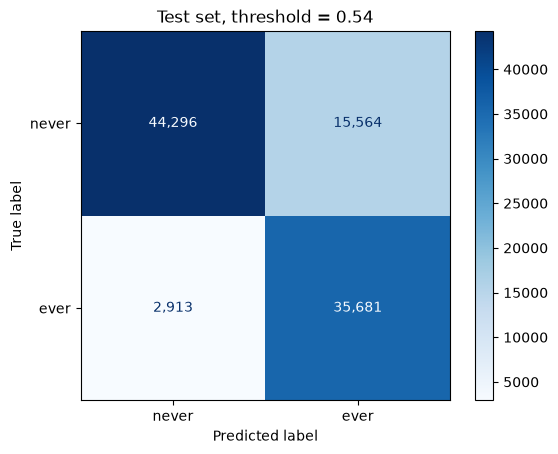

Ever-smokers detected : 35,681 of 38,594 (92.5%)
Never-smokers flagged : 15,564 of 59,860 (26.0%)


In [18]:
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["never", "ever"]).plot(cmap="Blues", values_format=",")
plt.title(f"Test set, threshold = {BEST_THRESHOLD:.2f}")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Ever-smokers detected : {tp:,} of {tp + fn:,} ({tp / (tp + fn):.1%})")
print(f"Never-smokers flagged : {fp:,} of {tn + fp:,} ({fp / (tn + fp):.1%})")

## 9. Complexity and computation cost

In [19]:
cost = {
    "n_parameters": N_PARAMS,
    "tuning_time_min": TUNING_TIME_S / 60,
    "tuning_trials_complete": N_COMPLETE,
    "tuning_trials_pruned": N_PRUNED,
    "final_train_time_min": FINAL_TRAIN_TIME_S / 60,
    "final_epochs_run": final["epochs_run"],
    "seconds_per_epoch_full_train": FINAL_TRAIN_TIME_S / final["epochs_run"],
    "inference_ms_per_10k_rows": INFERENCE_TIME_S / len(X_test) * 10_000 * 1000,
    "device": str(DEVICE),
}
pd.Series(cost).to_frame("value")

,value
n_parameters,271807
tuning_time_min,20.811256
tuning_trials_complete,20
tuning_trials_pruned,20
final_train_time_min,1.883382
final_epochs_run,10
seconds_per_epoch_full_train,11.300294
inference_ms_per_10k_rows,13.207086
device,mps


## 10. Export metrics

In [20]:
def to_builtin(x):
    if isinstance(x, dict):
        return {k: to_builtin(v) for k, v in x.items()}
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    return x

results = {
    "task": "task9_deep_neural_network",
    "problem": "never vs. ever smoked, from demographic and health measurements",
    "target": TARGET,
    "target_classes": meta["target_classes"],
    "input": "task4 output",
    "features": FEATURES,
    "model": "MLP: [Linear -> BatchNorm -> ReLU -> Dropout] x n_layers -> Linear(1)",
    "fixed_choices": {
        "loss": f"BCEWithLogitsLoss(pos_weight={POS_WEIGHT:.3f})",
        "optimiser": "AdamW",
        "early_stopping": f"val loss, patience {FINAL_PATIENCE}",
    },
    "tuning": {
        "method": "Optuna TPE + MedianPruner",
        "objective": "validation AUC",
        "sample_size": TUNE_SAMPLE,
        "n_trials": N_TRIALS,
        "trials_complete": N_COMPLETE,
        "trials_pruned": N_PRUNED,
        "best_value": study.best_value,
        "best_params": BEST_PARAMS,
        "param_importances": importances,
    },
    "threshold": {"value": BEST_THRESHOLD, "chosen_on": "validation set, max F1"},
    "metrics": {"validation": VAL_METRICS, "test": TEST_METRICS, "test_threshold_0.5": TEST_METRICS_05},
    "cost": cost,
    "quick_run": QUICK_RUN,
    "test_set_used": "once, in section 8",
}

with open(OUT_DIR / "task9_metrics.json", "w") as f:
    json.dump(to_builtin(results), f, indent=2)

print(f"Saved {OUT_DIR / 'task9_metrics.json'}")

Saved ../data/assignment3/task9_metrics.json
